In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn requests

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import io, zipfile, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme()

LOAD DATASET

In [3]:
DATA_URL = "https://archive.ics.uci.edu/static/public/2/adult.zip"
columns = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"
]

response = requests.get(DATA_URL, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    files = z.namelist()
    train_file = next(f for f in files if f.lower().endswith("adult.data"))
    test_file = next(f for f in files if f.lower().endswith("adult.test"))
    with z.open(train_file) as f:
        train_df = pd.read_csv(f, header=None, names=columns, skipinitialspace=True, na_values="?")
    with z.open(test_file) as f:
        test_df = pd.read_csv(
            f, header=None, names=columns, skipinitialspace=True,
            na_values="?", comment="|", skiprows=1
        )

df = pd.concat([train_df, test_df], ignore_index=True)
df["income"] = df["income"].astype(str).str.strip().str.rstrip(".")
df = df[df["income"].isin(["<=50K", ">50K"])].copy()

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (48842, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


Inspect structure and summary statistics

In [4]:
df.info()
display(df.describe(include="all").T)

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       46043 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education_num   48842 non-null  int64
 5   marital_status  48842 non-null  str  
 6   occupation      46033 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital_gain    48842 non-null  int64
 11  capital_loss    48842 non-null  int64
 12  hours_per_week  48842 non-null  int64
 13  native_country  47985 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,48842.0,NaN,NaN,NaN,38.643585,13.71051,17.0,28.0,37.0,48.0,90.0
workclass,46043,8,Private,33906,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,48842.0,NaN,NaN,NaN,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education,48842,16,HS-grad,15784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education_num,48842.0,NaN,NaN,NaN,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
marital_status,48842,7,Married-civ-spouse,22379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,46033,14,Prof-specialty,6172,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,48842,6,Husband,19716,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,48842,5,White,41762,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,48842,2,Male,32650,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Find missing values and duplicates

,Missing Count,Missing Percent
occupation,2809,5.75
workclass,2799,5.73
native_country,857,1.75
fnlwgt,0,0.00
education,0,0.00
education_num,0,0.00
age,0,0.00
marital_status,0,0.00
relationship,0,0.00
sex,0,0.00


Duplicate rows: 52


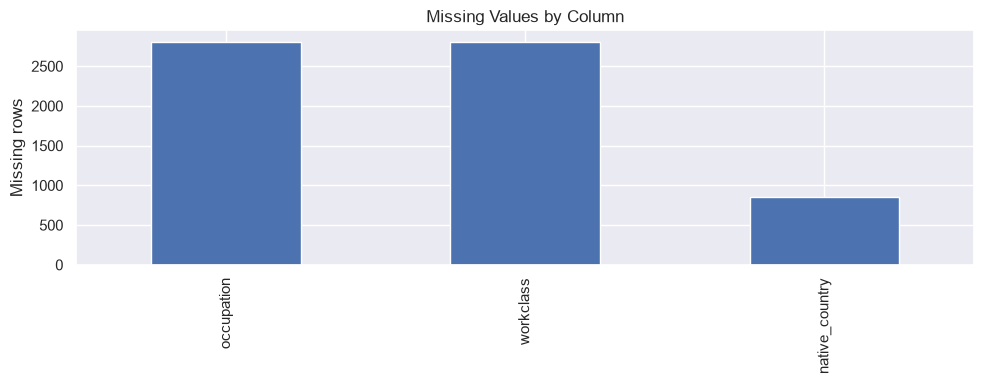

In [5]:
missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percent": (df.isna().mean() * 100).round(2)
}).sort_values("Missing Count", ascending=False)
display(missing)
print("Duplicate rows:", df.duplicated().sum())

missing_nonzero = df.isna().sum().sort_values(ascending=False)
missing_nonzero = missing_nonzero[missing_nonzero > 0]
if len(missing_nonzero):
    missing_nonzero.plot(kind="bar", figsize=(10, 4), title="Missing Values by Column")
    plt.ylabel("Missing rows")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

Clean duplicates and inspect target distribution

Duplicate rows removed: 52
Shape after duplicate removal: (48790, 15)


,Count
income,
<=50K,37109
>50K,11681


,Percent
income,
<=50K,76.06
>50K,23.94


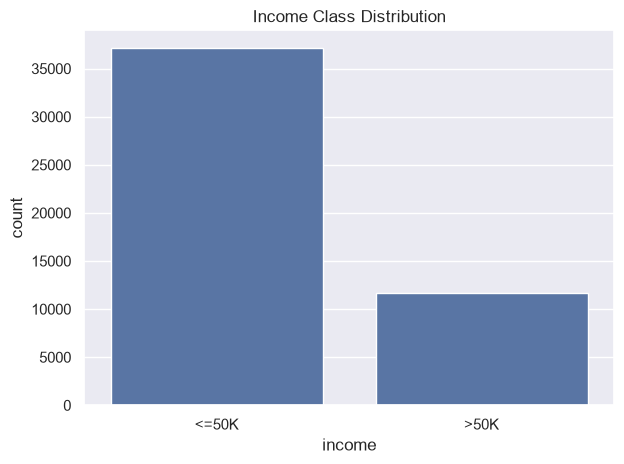

In [6]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicate rows removed:", before - len(df))
print("Shape after duplicate removal:", df.shape)

display(df["income"].value_counts().to_frame("Count"))
display((df["income"].value_counts(normalize=True) * 100).round(2).to_frame("Percent"))

sns.countplot(data=df, x="income")
plt.title("Income Class Distribution")
plt.tight_layout()
plt.show()

Exploratory data analysis

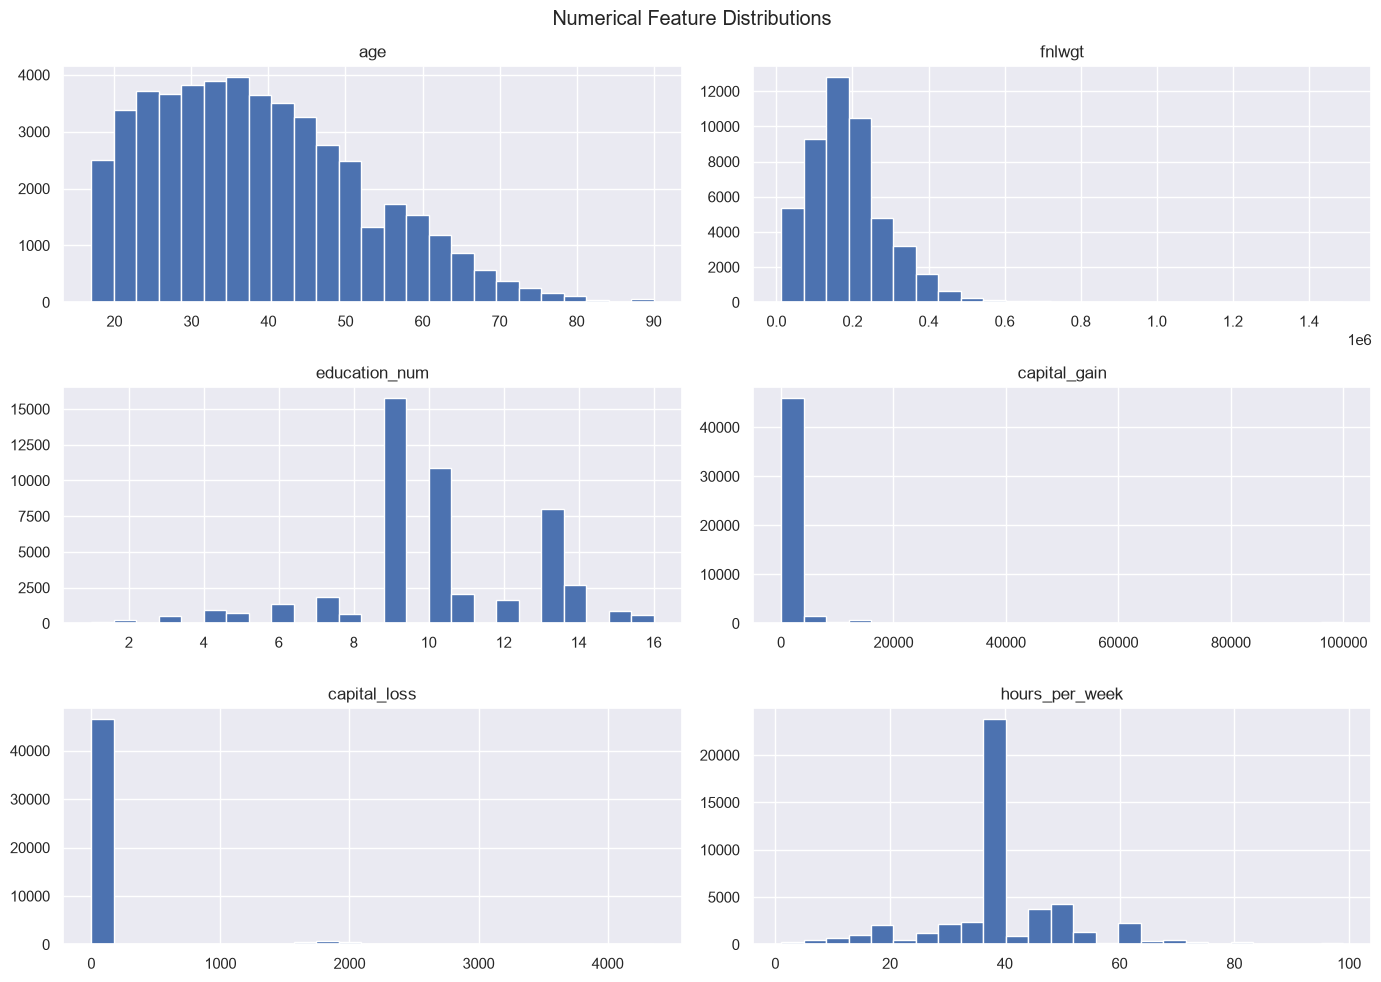

In [7]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
df[numeric_columns].hist(figsize=(14, 10), bins=25)
plt.suptitle("Numerical Feature Distributions")
plt.tight_layout()
plt.show()

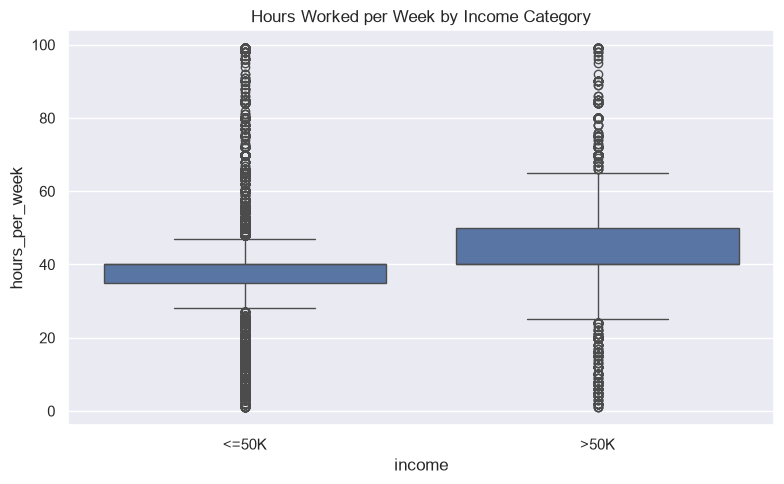

In [8]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="income", y="hours_per_week")
plt.title("Hours Worked per Week by Income Category")
plt.tight_layout()
plt.show()

Define features and target

In [9]:
# Target: 0 means <=50K, 1 means >50K
X = df.drop(columns=["income"])
y = df["income"].map({"<=50K": 0, ">50K": 1})

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Target labels: 0 = <=50K; 1 = >50K")

Feature shape: (48790, 14)
Target shape: (48790,)
Target labels: 0 = <=50K; 1 = >50K


Train/test split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Training class proportions:")
display(y_train.value_counts(normalize=True).rename("Proportion"))
print("Test class proportions:")
display(y_test.value_counts(normalize=True).rename("Proportion"))

Training rows: 39032
Test rows: 9758
Training class proportions:


income
0    0.760581
1    0.239419
Name: Proportion, dtype: float64

Test class proportions:


income
0    0.760607
1    0.239393
Name: Proportion, dtype: float64

Preprocessing

In [11]:
categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
numerical_features = X_train.select_dtypes(include=np.number).columns.tolist()

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, numerical_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
Categorical features: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']


C:\Users\Aditya\AppData\Local\Temp\ipykernel_27360\2874642835.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()


Define four algorithms

In [12]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=12, min_samples_leaf=5, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=150, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=3, random_state=RANDOM_STATE
    )
}
print("Algorithms:", list(models.keys()))

Algorithms: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting']


Train and evaluate all models

In [13]:
trained_models, predictions, probabilities, results = {}, {}, {}, []

for name, algorithm in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", algorithm)
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    trained_models[name] = pipeline
    predictions[name] = y_pred
    probabilities[name] = y_prob
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

comparison = pd.DataFrame(results).sort_values("F1", ascending=False).reset_index(drop=True)
display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Gradient Boosting,0.8704,0.7909,0.6233,0.6972,0.9248
1,Random Forest,0.8682,0.7769,0.6306,0.6961,0.9213
2,Decision Tree,0.8614,0.7526,0.6276,0.6844,0.8963
3,Logistic Regression,0.8520,0.7304,0.6053,0.6620,0.9081


Compare model metrics

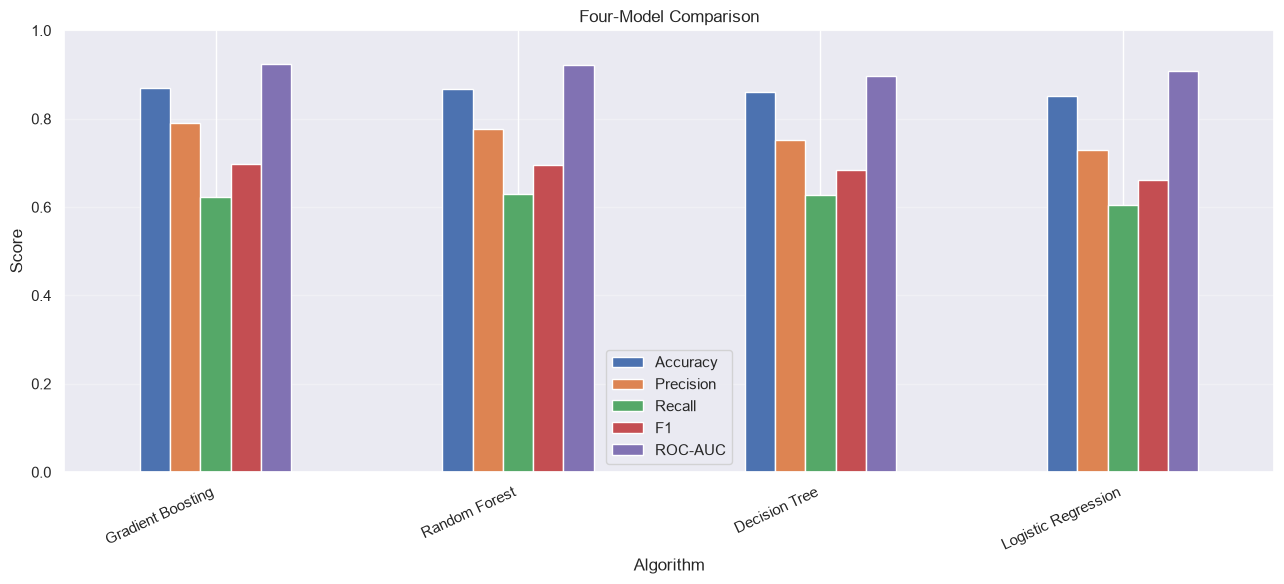

In [14]:
metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
ax = comparison.set_index("Model")[metrics].plot(
    kind="bar", figsize=(13, 6), ylim=(0, 1), title="Four-Model Comparison"
)
ax.set_ylabel("Score")
ax.set_xlabel("Algorithm")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Confusion matrices

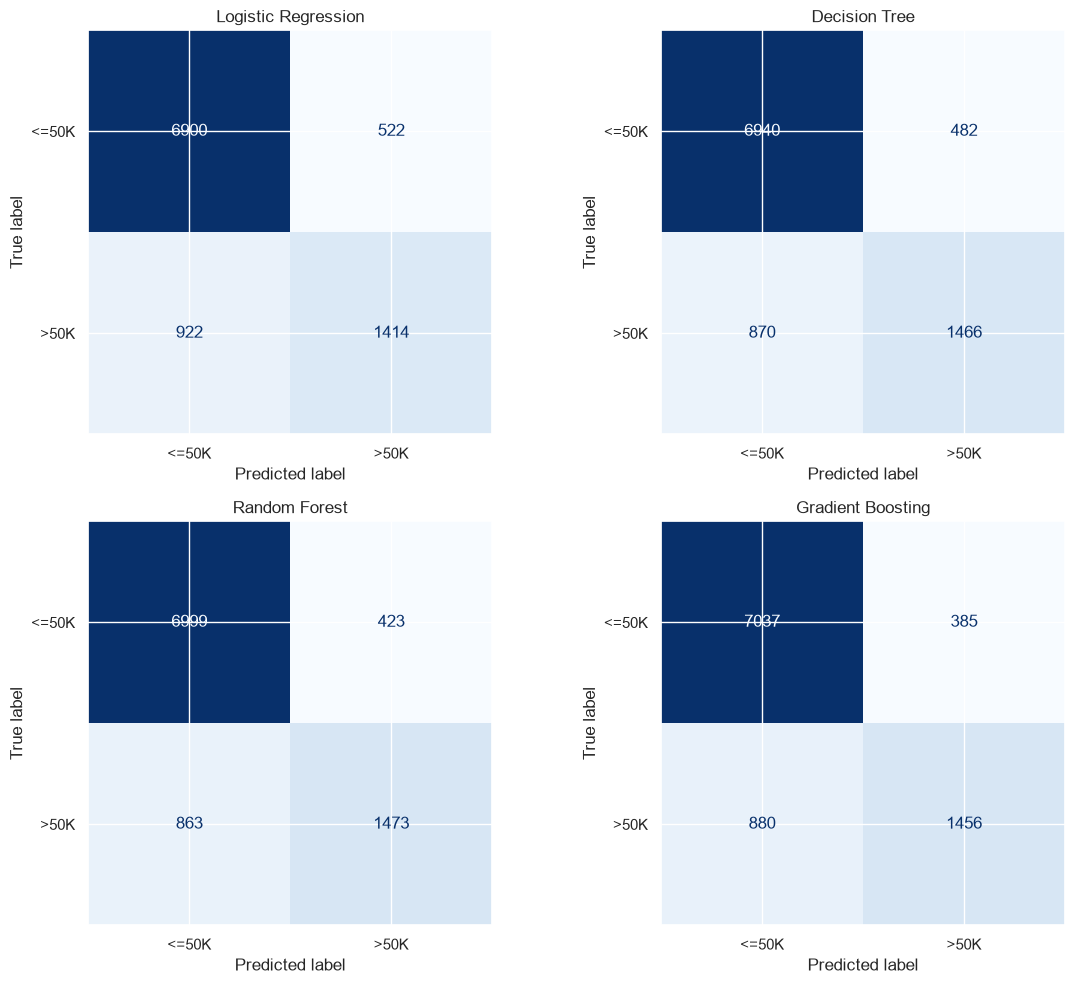

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=["<=50K", ">50K"],
        cmap="Blues", ax=ax, colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

ROC curve comparison

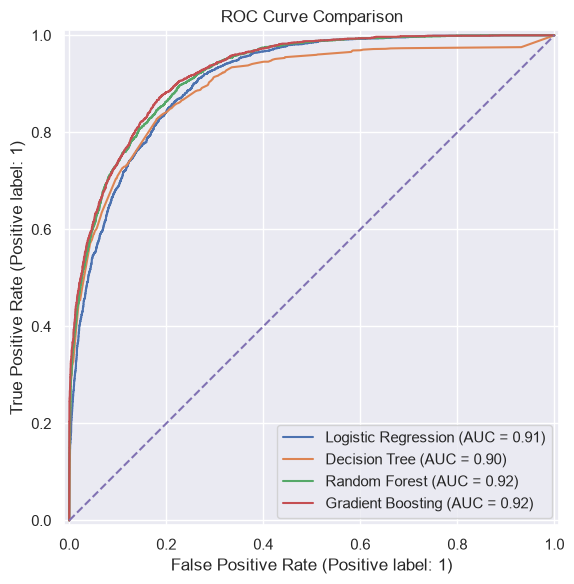

In [16]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, y_prob in probabilities.items():
    RocCurveDisplay.from_predictions(y_test, y_prob, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
ax.set_title("ROC Curve Comparison")
plt.tight_layout()
plt.show()

Review the leading model

In [17]:
best_name = comparison.iloc[0]["Model"]
print("Highest test F1 in this run:", best_name)
print(classification_report(
    y_test, predictions[best_name],
    target_names=["<=50K", ">50K"], zero_division=0
))

Highest test F1 in this run: Gradient Boosting
              precision    recall  f1-score   support

       <=50K       0.89      0.95      0.92      7422
        >50K       0.79      0.62      0.70      2336

    accuracy                           0.87      9758
   macro avg       0.84      0.79      0.81      9758
weighted avg       0.87      0.87      0.86      9758



Feature importance for tree models

Top 15 features: Decision Tree


,Feature,Importance
32,categorical__marital_status_Married-civ-spouse,0.377463
2,numeric__education_num,0.201103
3,numeric__capital_gain,0.182556
4,numeric__capital_loss,0.068867
0,numeric__age,0.049725
5,numeric__hours_per_week,0.036155
1,numeric__fnlwgt,0.024597
40,categorical__occupation_Exec-managerial,0.010156
44,categorical__occupation_Other-service,0.007205
11,categorical__workclass_Self-emp-not-inc,0.005898


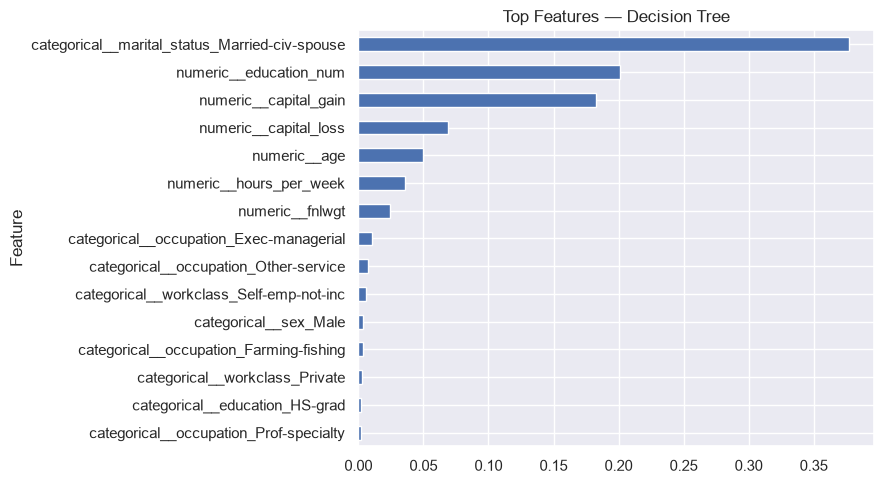

Top 15 features: Random Forest


,Feature,Importance
3,numeric__capital_gain,0.141973
0,numeric__age,0.097837
32,categorical__marital_status_Married-civ-spouse,0.092963
2,numeric__education_num,0.088730
51,categorical__relationship_Husband,0.079791
1,numeric__fnlwgt,0.064341
5,numeric__hours_per_week,0.063528
34,categorical__marital_status_Never-married,0.043759
4,numeric__capital_loss,0.037259
40,categorical__occupation_Exec-managerial,0.024621


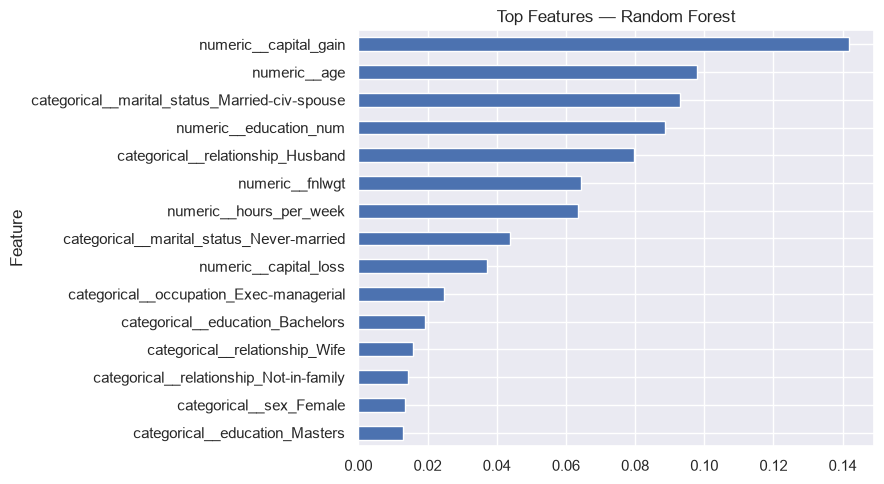

Top 15 features: Gradient Boosting


,Feature,Importance
32,categorical__marital_status_Married-civ-spouse,0.390829
2,numeric__education_num,0.201186
3,numeric__capital_gain,0.200438
0,numeric__age,0.058273
4,numeric__capital_loss,0.058102
5,numeric__hours_per_week,0.038199
40,categorical__occupation_Exec-managerial,0.015214
44,categorical__occupation_Other-service,0.006630
41,categorical__occupation_Farming-fishing,0.005326
11,categorical__workclass_Self-emp-not-inc,0.004390


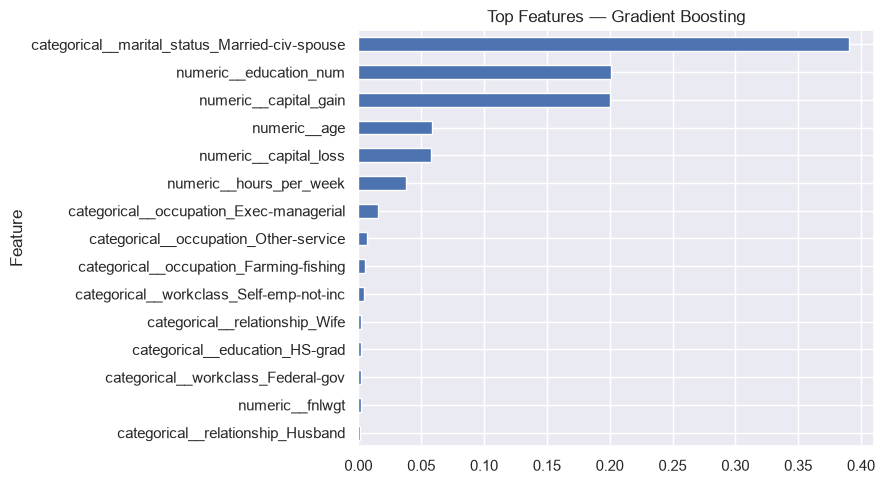

In [18]:
for name in ["Decision Tree", "Random Forest", "Gradient Boosting"]:
    pipeline = trained_models[name]
    classifier = pipeline.named_steps["classifier"]
    feature_names = pipeline.named_steps["preprocessor"].get_feature_names_out()
    importance = pd.DataFrame({
        "Feature": feature_names,
        "Importance": classifier.feature_importances_
    }).sort_values("Importance", ascending=False).head(15)

    print("Top 15 features:", name)
    display(importance)
    importance.sort_values("Importance").plot(
        x="Feature", y="Importance", kind="barh", legend=False,
        figsize=(9, 5), title=f"Top Features — {name}"
    )
    plt.tight_layout()
    plt.show()